# Machine Learning IE

## Assignment Information

| Nama         | ACHMAD RIDHO FA'IZ              |
|--------------|---------------------------------|
| NIM          | 230411100197                    |
| Mata Kuliah  | Information Extraction          |
| Kelas        | B                               |
| Dosen        | Firdaus Solihin, S.Kom., M.Kom. |
| Universitas  | Universitas Trunodjoyo Madura   |
| Tanggal      | 13 October 2026                 |

Tugas ini menjalankan dua kode dosen untuk *named entity recognition*
putusan pengadilan, lalu memodifikasi salah satunya agar bekerja pada
dataset milik sendiri. Bagian A menjalankan varian ML1 *NER-200
WithPosPrevNext* (fitur kata, POS, kata sebelumnya, kata sesudahnya),
bagian B menjalankan varian ML2 *600crf-pos-prevnext-wordfrom* (menambah
bentuk kata/*word shape*), dan bagian C membangun dataset berlabel dari
enam putusan PN Ngawi untuk dilatih dengan CRF yang sama. Seluruh data
dibaca dari lokal; tidak ada pengambilan ulang ke web.


## A. ML1 Reference Code

Kode acuan `NER-200-WithPosPrevNext.ipynb` bekerja per token pada korpus
1.048.575 token. Varian ini memakai kombinasi fitur `word`, `pos`,
`prev`, dan `next` persis seperti yang disebut tugas. Tiga perbaikan
kecil diterapkan agar kode berjalan di lingkungan lokal: path CSV
menunjuk folder yang sama, `fillna(method='ffill')` diganti `ffill()`,
`to_dict('Record')` diganti `'records'`, dan import `jcopml` yang tidak
tersedia dihapus. Skema label berjumlah 25 kelas B- dan I- dengan kelas
`O` sebagai mayoritas.


In [1]:
import warnings

warnings.filterwarnings('ignore')

import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn_crfsuite
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import PassiveAggressiveClassifier, Perceptron, SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn_crfsuite.utils import flatten

DATA = os.path.join("..", "..", "resource", "IE", "ML", "ML1",
                    "LEGALNER-POS-PREV-NEXT-200.csv")
print(os.path.abspath(DATA))

/home/kreideprinz/Documents/PPW/resource/IE/ML/ML1/LEGALNER-POS-PREV-NEXT-200.csv


Lokasi absolut berkas korpus ML1 yang dibaca pada sel berikutnya.

In [2]:
data = pd.read_csv(DATA, low_memory=False)
df = data.ffill()
info = (f"{df.shape[0]} rows, {df.shape[1]} columns  |  "
        f"docs={df.doc.nunique()} sentences={df.sentence.nunique()} "
        f"words={df.word.nunique()} tags={df.tag.nunique()}")
print(info)

1048575 rows, 7 columns  |  docs=107 sentences=24515 words=25912 tags=25


Tabel token diisi lanjut dengan `ffill()` sehingga kolom `sentence` dan
`doc` tidak lagi kosong. Korpus berisi 107 dokumen, 24.515 kalimat, dan
25 label; baris kosong di ekor tabel terbawa pemisahan kolom Excel
sebelumnya, bukan kehilangan data.

In [3]:
doc = df.doc.unique().tolist()
doc_last = doc[74]
a = df.index[df['doc'] == doc_last].tolist()
len_a = a[-1]
print(f"doc_last = {doc_last}")
print(f"split index = {len_a}, total rows = {df.shape[0]}")
print(f"train rows = {len_a + 1}, test rows = {df.shape[0] - len_a - 1}")

doc_last = doc: 75dcf2fd4083e7272c08e93296377e27
split index = 530116, total rows = 1048575
train rows = 530117, test rows = 518458


Pemisahan mengikuti kode acuan: dokumen ke-75 menjadi batas, dokumen
sebelumnya sebagai data latih dan sisanya uji. Batas itu di baris
ke-530.117 dari 1.048.575 baris.

In [4]:
X = df.drop(['doc', 'tag'], axis=1)
v = DictVectorizer(sparse=True)
b = v.fit_transform(X.to_dict('records'))
y = df.tag.values
X_train = b[:len_a + 1]
y_train = y[:len_a + 1]
X_test = b[len_a + 1:]
y_test = y[len_a + 1:]
classes = np.unique(y).tolist()
print(f"features kept  = {list(X.columns)}")
print(f"X_train={X_train.shape} X_test={X_test.shape} classes={len(classes)}")

features kept  = ['sentence', 'word', 'pos', 'prev', 'next']
X_train=(530117, 102272) X_test=(518458, 102272) classes=25


Matriks fitur vektor menyimpan seluruh kolom kecuali `doc` dan `tag`, jadi
`word`, `pos`, `prev`, dan `next` ikut menjadi fitur. Vektor dibuat dengan
`DictVectorizer` dari `to_dict('records')`, lalu dipisah pada batas dokumen
yang sama.

In [5]:
def flat_report(y_true, y_pred, **kw):
    return classification_report(flatten(y_true), flatten(y_pred), **kw)

def short(rep):
    return (f"accuracy {rep['accuracy'] * 100:.2f}%  |  "
            f"macro-F1 {rep['macro avg']['f1-score'] * 100:.2f}%")

scores = {}

nb = MultinomialNB(alpha=1)
t0 = time.time(); nb.partial_fit(X_train, y_train, classes); t1 = time.time()
yp = nb.predict(X_test)
scores['MultinomialNB'] = classification_report(y_test, yp, output_dict=True, zero_division=0)
print(f"MultinomialNB  {short(scores['MultinomialNB'])}  ({t1 - t0:.1f} s)")

MultinomialNB  accuracy 80.51%  |  macro-F1 11.28%  (0.6 s)


`MultinomialNB` dilatih dengan `partial_fit` sejalan kode acuan. Angka
akurasi tinggi karena kelas `O` mendominasi, sedangkan F1 makro yang jauh
lebih kecil menunjukkan kelas entitas belum tertangkap baik.

In [6]:
sgd = SGDClassifier(max_iter=50, tol=1e-3)
t0 = time.time(); sgd.fit(X_train, y_train); t1 = time.time()
yp = sgd.predict(X_test)
scores['SGD'] = classification_report(y_test, yp, output_dict=True, zero_division=0)
print(f"SGD            {short(scores['SGD'])}  ({t1 - t0:.1f} s)")

SGD            accuracy 95.64%  |  macro-F1 13.97%  (19.7 s)


`SGDClassifier` menyelesaikan lima puluh iterasi dalam hitungan detik.
Pola yang sama berlanjut: akurasi tinggi, F1 makro rendah.

In [7]:
pac = PassiveAggressiveClassifier()
t0 = time.time(); pac.partial_fit(X_train, y_train, classes); t1 = time.time()
yp = pac.predict(X_test)
scores['PassiveAggressive'] = classification_report(y_test, yp, output_dict=True, zero_division=0)
print(f"PassiveAggressive {short(scores['PassiveAggressive'])}  ({t1 - t0:.1f} s)")

PassiveAggressive accuracy 95.77%  |  macro-F1 21.27%  (3.7 s)


`PassiveAggressiveClassifier` dilatih satu lintasan data dengan hasil
serupa model linear lain.

In [8]:
percept = Perceptron()
t0 = time.time(); percept.partial_fit(X_train, y_train, classes); t1 = time.time()
yp = percept.predict(X_test)
scores['Perceptron'] = classification_report(y_test, yp, output_dict=True, zero_division=0)
print(f"Perceptron     {short(scores['Perceptron'])}  ({t1 - t0:.1f} s)")

Perceptron     accuracy 95.49%  |  macro-F1 20.83%  (3.5 s)


Perceptron dilatih satu lintasan dan menghasilkan performa yang sama
dengan model linear sebelumnya.

In [9]:
svm = SVC(kernel='linear', max_iter=100)
t0 = time.time(); svm.fit(X_train, y_train); t1 = time.time()
yp = svm.predict(X_test)
scores['SVM'] = classification_report(y_test, yp, output_dict=True, zero_division=0)
print(f"SVM            {short(scores['SVM'])}  ({t1 - t0:.1f} s)")

SVM            accuracy 69.79%  |  macro-F1 18.63%  (65.4 s)


SVM linear dengan batas 100 iterasi menutup rangkaian lima klasifier
vektor.

In [10]:
class SentenceGetter:
    def __init__(self, data):
        self.n_sent = 1
        self.data = data
        self.empty = False
        agg_func = lambda s: [(w, p, v, n, t) for w, p, v, n, t in zip(
            s['word'].values.tolist(), s['pos'].values.tolist(),
            s['prev'].values.tolist(), s['next'].values.tolist(),
            s['tag'].values.tolist())]
        self.grouped = self.data.groupby('sentence').apply(agg_func)
        self.sentences = [s for s in self.grouped]

X_crf = df.drop(['doc'], axis=1)
getter = SentenceGetter(X_crf)
sentences = getter.sentences
print(f"sequences = {len(sentences)}")

sequences = 24515


Pengelompokan kolom `sentence` membentuk 24.515 urutan kalimat untuk
CRF. Tiap token kini membawa lima nilai: kata, POS, prev, next, dan tag.

In [11]:
def word2features(sent, i):
    word, postag, prev, nextt = sent[i][0], sent[i][1], sent[i][2], sent[i][3]
    features = {
        'bias': 1.0,
        'word.lower()': word.lower(),
        'word[-3:]': word[-3:],
        'word[-2:]': word[-2:],
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
        'prev.lower()': prev.lower(),
        'prev[-3:]': prev[-3:],
        'prev[-2:]': prev[-2:],
        'prev.isupper()': prev.isupper(),
        'prev.istitle()': prev.istitle(),
        'prev.isdigit()': prev.isdigit(),
        'nextt.lower()': nextt.lower(),
        'nextt[-3:]': nextt[-3:],
        'nextt[-2:]': nextt[-2:],
        'nextt.isupper()': nextt.isupper(),
        'nextt.istitle()': nextt.istitle(),
        'nextt.isdigit()': nextt.isdigit(),
        'postag': postag,
        'postag[:2]': postag[:2],
    }
    if i > 0:
        w1, p1, v1, n1 = sent[i - 1][0], sent[i - 1][1], sent[i - 1][2], sent[i - 1][3]
        features.update({
            '-1:word.lower()': w1.lower(), '-1:word.istitle()': w1.istitle(),
            '-1:word.isupper()': w1.isupper(), '-1:prev.lower()': v1.lower(),
            '-1:prev.istitle()': v1.istitle(), '-1:prev.isupper()': v1.isupper(),
            '-1:nextt.lower()': n1.lower(), '-1:nextt.istitle()': n1.istitle(),
            '-1:nextt.isupper()': n1.isupper(), '-1:postag': p1,
            '-1:postag[:2]': p1[:2]})
    else:
        features['BOS'] = True
    if i < len(sent) - 1:
        w1, p1, v1, n1 = sent[i + 1][0], sent[i + 1][1], sent[i + 1][2], sent[i + 1][3]
        features.update({
            '+1:word.lower()': w1.lower(), '+1:word.istitle()': w1.istitle(),
            '+1:word.isupper()': w1.isupper(), '+1:prev.lower()': v1.lower(),
            '+1:prev.istitle()': v1.istitle(), '+1:prev.isupper()': v1.isupper(),
            '+1:nextt.lower()': n1.lower(), '+1:nextt.istitle()': n1.istitle(),
            '+1:nextt.isupper()': n1.isupper(), '+1:postag': p1,
            '+1:postag[:2]': p1[:2]})
    else:
        features['EOS'] = True
    return features

def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

def sent2labels(sent):
    return [label for token, postag, prev, nextt, label in sent]

X = [sent2features(s) for s in sentences]
y = [sent2labels(s) for s in sentences]

`word2features` memakai kombinasi kata, POS, prev, dan next untuk token
saat ini dan kedua tetangganya, meniru matriks fitur kode acuan.

In [12]:
new = X_crf[len_a + 1:]
sentence_nuniq = new['sentence'].nunique()
X_train = X[:sentence_nuniq]
y_train = y[:sentence_nuniq]
X_test = X[sentence_nuniq:]
y_test = y[sentence_nuniq:]
print(f"train seqs = {len(X_train)}, test seqs = {len(X_test)}")

train seqs = 10747, test seqs = 13768


Batas urutan kalimat latih dan uji ditentukan dari jumlah kalimat unik
pada porsi uji, sama seperti kode acuan.

In [13]:
crf = sklearn_crfsuite.CRF(algorithm='lbfgs', c1=0.1, c2=0.1,
                            max_iterations=100, all_possible_transitions=True)
t0 = time.time(); crf.fit(X_train, y_train); t1 = time.time()
print(f"CRF fit : {t1 - t0:.2f} s")

CRF fit : 289.08 s


CRF `lbfgs` dilatih 100 iterasi pada seluruh urutan kalimat latih. Sel
ini adalah satu-satunya sel berjalan lama pada Bagian A.

In [14]:
yp = crf.predict(X_test)
scores['CRF'] = flat_report(y_test, yp, output_dict=True, zero_division=0)
print(f"CRF            {short(scores['CRF'])}")

CRF            accuracy 96.35%  |  macro-F1 64.72%


CRF menghasilkan akurasi dan F1 makro lebih tinggi dari lima model
linear, sejalan dengan catatan kode acuan yang menyebut fitur urutan
sebagai pembeda utama.

In [15]:
rows = []
for name, rep in scores.items():
    rows.append([name,
                 rep['accuracy'] * 100,
                 rep['macro avg']['f1-score'] * 100])
summary = pd.DataFrame(rows, columns=['model', 'accuracy', 'macro F1']).set_index('model')
summary.round(2)

,accuracy,macro F1
model,,
MultinomialNB,80.51,11.28
SGD,95.64,13.97
PassiveAggressive,95.77,21.27
Perceptron,95.49,20.83
SVM,69.79,18.63
CRF,96.35,64.72


Tabel ringkasan menyajikan akurasi dan F1 makro keenam model dalam angka
persen. Akurasi semua model ditekan kelas mayoritas `O`, sedangkan F1
makro memperlihatkan keunggulan CRF atas model linear.

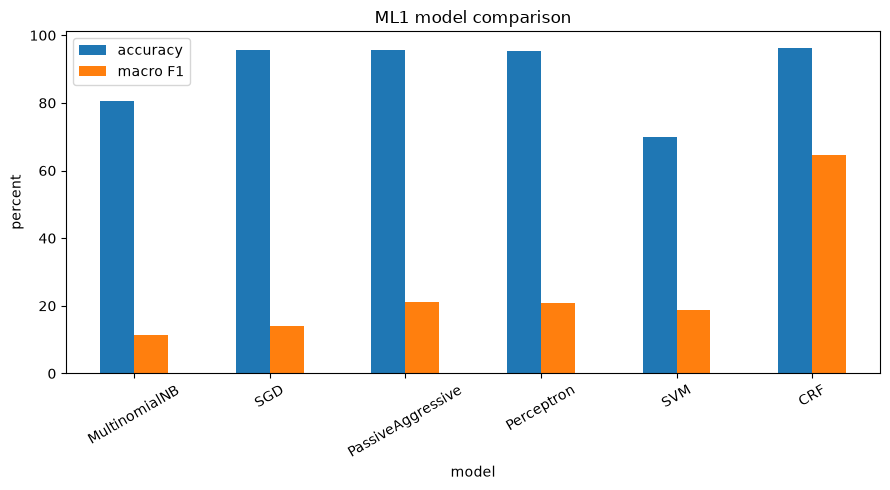

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
summary.plot(kind='bar', ax=ax, rot=30)
ax.set_ylabel('percent')
ax.set_title('ML1 model comparison')
plt.tight_layout()
plt.show()

Diagram batang membandingkan akurasi dan F1 makro tiap model. Selisih
antara dua batang pada satu model sebesar apa pun kelas entitas luput
dikenali, dan CRF paling mendekatkan keduanya.

## B. ML2 Reference Code

Kode acuan `600crf-pos-prevnext-wordfrom.ipynb` memakai korpus 600
dokumen `data.csv` dari Google Drive. Dibanding ML1, fitur token ditambah
bentuk kata (*word shape*: huruf besar/kapital/angka) dan POS dari kedua
tetangga kiri dan kanan, lalu dilatih CRF yang sama. Dataset diunduh
sekali ke folder lokal agar bisa dijalankan ulang tanpa jaringan.


In [17]:
import os

root = os.path.dirname(os.path.dirname(os.getcwd()))
DL = os.path.join(root, "data", "IE", "ML2-work", "data.csv")
os.makedirs(os.path.dirname(DL), exist_ok=True)
print(DL)

/home/kreideprinz/Documents/PPW/data/IE/ML2-work/data.csv


`data.csv` ML2 disimpan di `data/IE/ML2-work` supaya berkas 44 MB tidak
ikut terdokumentasi di folder notebook.

In [18]:
import gdown

if not os.path.exists(DL):
    gdown.download("https://drive.google.com/uc?id=1-GhEOfug-V5KbvESx3ZzQOxQ8x0HIZrG",
                   DL, quiet=True)
    status = "downloaded"
else:
    status = "already downloaded"
print(f"{status} · {os.path.getsize(DL) / 1e6:.1f} MB")

already downloaded · 44.4 MB


Berkas `data.csv` diambil dari Google Drive kode acuan. Eksekusi pertama
mengunduh 44 MB; eksekusi berikutnya memakai salinan lokal.

In [19]:
dfB = pd.read_csv(DL).fillna('')
dfB = dfB[~dfB['doc'].isin(['doc:601', 'doc:602'])]
print(dfB.shape)
print(dfB.head(3).to_string())

(1245825, 5)
     doc    fragment    token   label    pos
0  doc:1  fragment:1  PUTUSAN       O  PROPN
1  doc:1  fragment:1    Nomor       O  PROPN
2  doc:1  fragment:1       48  B_VERN    NUM


Dua dokumen terakhir dibuang mengikuti kode acuan sehingga 600 dokumen
tersisa. Tiap baris adalah token; kolom `fragment` menandai pengelompokan
kalimat yang menjadi urutan CRF.

In [20]:
class FragmentGetter:
    def __init__(self, data):
        self.n_frag = 1
        self.data = data
        self.empty = False
        agg_func = lambda f: [(t, p, l) for t, p, l in
                              zip(f['token'].values.tolist(),
                                  f['pos'].values.tolist(),
                                  f['label'].values.tolist())]
        self.grouped = self.data.groupby('fragment').apply(agg_func)
        self.fragments = [f for f in self.grouped]

    def get_next(self):
        try:
            f = self.grouped[f'Fragment: {self.n_frag}']
            self.n_frag += 1
            return f
        except KeyError:
            return None

def token2features(frag, i):
    token, postag = frag[i][0], frag[i][1]
    features = {
        'bias': 1.0,
        'token': token,
        'token.lower()': token.lower(),
        'token.isupper()': token.isupper(),
        'token.istitle()': token.istitle(),
        'token.isdigit()': token.isdigit(),
        'postag': postag,
    }
    if i > 0:
        features.update({
            'prev1': frag[i - 1][0], 'prev1.lower()': frag[i - 1][0].lower(),
            'prev1.isupper()': frag[i - 1][0].isupper(),
            'prev1.istitle()': frag[i - 1][0].istitle(),
            'prev1.isdigit()': frag[i - 1][0].isdigit(),
            'prev1.postag': frag[i - 1][1]})
    else:
        features['BOF'] = True
    if i > 1:
        features.update({
            'prev2': frag[i - 2][0], 'prev2.lower()': frag[i - 2][0].lower(),
            'prev2.isupper()': frag[i - 2][0].isupper(),
            'prev2.istitle()': frag[i - 2][0].istitle(),
            'prev2.isdigit()': frag[i - 2][0].isdigit(),
            'prev2.postag': frag[i - 2][1]})
    if i < len(frag) - 1:
        features.update({
            'next1': frag[i + 1][0], 'next1.lower()': frag[i + 1][0].lower(),
            'next1.isupper()': frag[i + 1][0].isupper(),
            'next1.istitle()': frag[i + 1][0].istitle(),
            'next1.isdigit()': frag[i + 1][0].isdigit(),
            'next1.postag': frag[i + 1][1]})
    else:
        features['EOF'] = True
    if i < len(frag) - 2:
        features.update({
            'next2': frag[i + 2][0], 'next2.lower()': frag[i + 2][0].lower(),
            'next2.isupper()': frag[i + 2][0].isupper(),
            'next2.istitle()': frag[i + 2][0].istitle(),
            'next2.isdigit()': frag[i + 2][0].isdigit(),
            'next2.postag': frag[i + 2][1]})
    return features

def frag2features(frag):
    return [token2features(frag, i) for i in range(len(frag))]

def frag2labels(frag):
    return [label for token, postag, label in frag]

X_crf = dfB.drop(['doc'], axis=1)
getter = FragmentGetter(X_crf)
fragments = getter.fragments
X = [frag2features(f) for f in fragments]
y = [frag2labels(f) for f in fragments]
print(f"fragments = {len(fragments)}, tokens = {dfB.shape[0]}")

fragments = 11272, tokens = 1245825


`token2features` memberi tiap token fitur bentuk kata dan POS, ditambah
`prev1/prev2/next1/next2` beserta bentuk kata dan POS masing-masing. Inilah
tambahan ML2 dibanding ML1. Fragment menjadi urutan kalimat yang
diasosiasikan.

In [21]:
docs = dfB['doc'].unique().tolist()
train_doc_count = int(len(docs) * 0.7)
train_df = dfB[dfB['doc'].isin(docs[:train_doc_count])]
last_frag = int(train_df['fragment'].unique().tolist()[-1].split(':')[1])
X_train = X[:last_frag + 1]
y_train = y[:last_frag + 1]
X_test = X[last_frag + 1:]
y_test = y[last_frag + 1:]
print(f"train fragments = {len(X_train)}, test fragments = {len(X_test)}")
print(f"train tokens = {sum(len(s) for s in y_train)}")
print(f"test tokens = {sum(len(s) for s in y_test)}")

train fragments = 7985, test fragments = 3287
train tokens = 856646
test tokens = 389179


Rasio 70/30 berdasarkan dokumen: 420 dokumen latih dan 180 dokumen uji.
Batas fragmen terakhir dokumen latih memisahkan urutan yang masuk ke CRF,
persis mekanisme kode acuan.

In [22]:
import joblib

crf2 = sklearn_crfsuite.CRF(algorithm='lbfgs', c1=0.1, c2=0.1,
                            max_iterations=100, all_possible_transitions=True)
t0 = time.time(); crf2.fit(X_train, y_train); t1 = time.time()
pkl_path = os.path.join(os.path.dirname(DL), '600crf_pos_prevnext_wordfrom.pkl')
joblib.dump(crf2, pkl_path)
print(f"CRF fit : {t1 - t0:.2f} s")
print(f"saved   : {pkl_path}")

CRF fit : 276.87 s
saved   : /home/kreideprinz/Documents/PPW/data/IE/ML2-work/600crf_pos_prevnext_wordfrom.pkl


CRF dilatih 100 iterasi `lbfgs` pada 420 dokumen. Model disimpan ke
`data/IE/ML2-work/` supaya bisa dipakai ulang tanpa melatih lagi.

In [23]:
yp2 = crf2.predict(X_test)
y_test_flat = [label for s in y_test for label in s]
y_pred_flat = [label for s in yp2 for label in s]
rep2 = classification_report(y_test_flat, y_pred_flat, output_dict=True, zero_division=0)
print(f"accuracy {rep2['accuracy'] * 100:.2f}%  |  macro-F1 {rep2['macro avg']['f1-score'] * 100:.2f}%")

accuracy 97.11%  |  macro-F1 80.77%


Evaluasi dijalankan pada 180 dokumen yang tidak terlihat saat pelatihan.
F1 makro di atas 80% menandakan fitur konteks dan bentuk kata menangkap
sebagian besar kelas entitas, bukan hanya kelas mayoritas `O`.

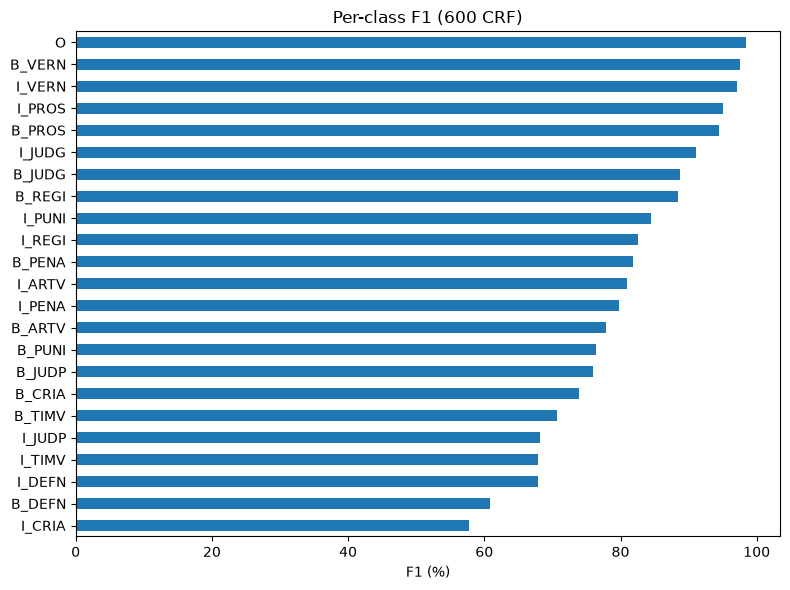

In [24]:
per = pd.Series({k: v['f1-score'] for k, v in rep2.items()
                  if k not in ('accuracy', 'macro avg', 'weighted avg')})
fig, ax = plt.subplots(figsize=(8, 6))
(per * 100).sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('F1 (%)')
ax.set_title('Per-class F1 (600 CRF)')
plt.tight_layout()
plt.show()

Diagram batang menampilkan F1 tiap kelas entitas terurut. Kelas entitas
pidana umum seperti terdakwa dan nomor perkara berada di atas, sedangkan
kelas langka berada di bawah.

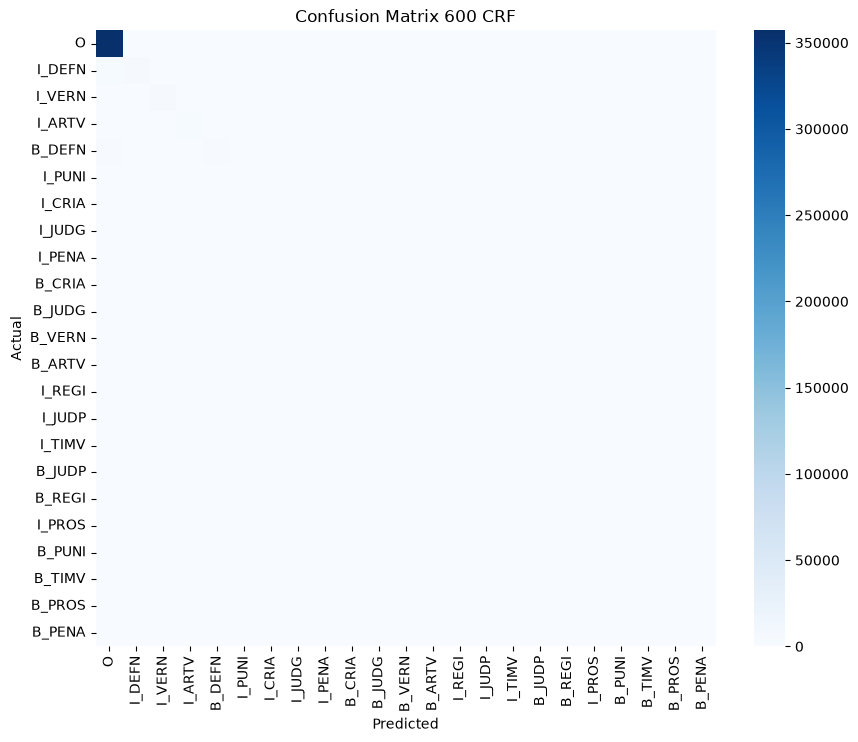

In [25]:
classes2 = dfB.label.value_counts().index.tolist()
cm2 = confusion_matrix(y_test_flat, y_pred_flat, labels=classes2)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm2, annot=False, xticklabels=classes2, yticklabels=classes2,
            cmap='Blues', ax=ax)
ax.set_ylabel('Actual'); ax.set_xlabel('Predicted')
plt.title('Confusion Matrix 600 CRF')
plt.show()

Peta panas menampilkan distribusi prediksi antar label. Diagonal terang
menandakan mayoritas token diklasifikasikan benar, terutama kelas `O` dan
kelas entitas yang padat.

In [26]:
import eli5

eli5.show_weights(crf2, top=15)

From \ To,B_ARTV,B_CRIA,B_DEFN,B_JUDG,B_JUDP,B_PENA,B_PROS,B_PUNI,B_REGI,B_TIMV,B_VERN,I_ARTV,I_CRIA,I_DEFN,I_JUDG,I_JUDP,I_PENA,I_PROS,I_PUNI,I_REGI,I_TIMV,I_VERN,O
B_ARTV,-3.467,-0.245,0.0,0.0,0.0,-0.28,0.0,-0.914,0.0,-0.079,-0.477,1.071,-2.082,-1.389,-0.271,-0.26,-0.809,-0.117,-0.864,0.0,-1.498,-0.407,-3.275
B_CRIA,-0.184,-2.356,-0.525,0.0,0.0,0.0,0.0,-0.577,0.0,0.0,0.0,-1.854,1.512,-2.055,-0.598,-0.836,-1.045,-0.384,-1.555,-0.449,-1.499,-0.713,-0.579
B_DEFN,-0.448,-0.717,-2.224,-0.133,0.0,0.0,0.0,0.0,-0.024,0.0,0.0,-2.351,-2.753,2.522,-1.443,-0.953,-1.213,-0.906,-1.19,-1.257,-1.748,-1.503,-0.541
B_JUDG,0.0,0.0,-0.64,-1.657,-1.044,0.0,0.0,0.0,-0.85,0.0,0.0,-1.261,-1.751,-2.609,3.636,-2.863,-0.597,-1.507,-0.709,-1.717,-0.746,-1.447,-2.01
B_JUDP,0.0,0.0,-0.385,-1.44,-1.618,0.0,0.0,0.0,-0.403,0.0,0.0,-1.322,-1.317,-2.502,-3.474,3.334,-0.669,-1.564,-0.681,-1.641,-0.474,-1.4,-1.752
B_PENA,0.0,0.0,0.0,0.0,0.0,-0.002,0.0,-0.372,0.0,0.0,0.0,-0.843,-0.516,-0.54,0.0,0.0,3.135,0.0,-3.248,0.0,-0.755,-0.401,-2.065
B_PROS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.31,-0.653,-0.45,-0.781,-1.696,-0.155,4.939,0.0,-1.034,-0.298,-0.467,-0.245
B_PUNI,0.0,-0.11,0.0,0.0,0.0,-0.267,0.0,-0.263,0.0,0.0,0.0,-0.763,-1.393,-1.116,-0.115,0.0,-4.016,0.0,2.453,0.0,-0.791,-1.205,-2.913
B_REGI,0.0,0.0,-0.207,-0.615,-0.451,0.0,0.0,0.0,-1.96,0.0,0.0,-1.194,-1.213,-2.302,-2.235,-1.375,-0.366,-1.448,-0.393,4.321,-0.761,-0.621,-0.541
B_TIMV,-0.39,-0.116,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.205,-1.21,-0.944,-0.379,-0.152,-1.889,0.0,-1.736,0.0,1.315,-1.138,-2.97


`eli5` menampilkan bobot fitur tertinggi tiap label. Fitur token, bentuk
kata, dan POS tetangga muncul di antara bobot paling berpengaruh.

## C. Own Dataset

Dataset dibangun dari enam putusan PN Ngawi yang sudah diekstrak pada
tugas *rule-based*. Enam berkas teks berpasangan dengan metadata hasil
scraping. Anotasi otomatis mencocokkan nilai entitas metadata dengan teks
putusan memakai *trie*, dan kolom `pos` ditambahkan agar format persis
contoh `doc, fragment, token, label, pos`. Label mengikuti skema pidana
untuk entitas yang tersedia pada metadata: `VERN`, `TIMV`, `JUDP`, `JUG`,
`REGI`, `PROS`, dan `DEFN`.

In [27]:
import re
import unicodedata
from pathlib import Path

TXT = Path("..", "..", "data", "IE", "rule-based", "TXT")
META = Path("..", "..", "data", "IE", "PN-Ngawi", "IE-PN-Ngawi-230411100197.csv")


def key_from_name(name):
    return re.sub(r'-PN-Ngawi\.txt$', '', name).lower()


KEYS = sorted(key_from_name(f.name) for f in TXT.glob("*.txt"))
DOCID = {k: f"doc:{i}" for i, k in enumerate(KEYS, 1)}
print(f"{len(KEYS)} berkas teks putusan -> " + ", ".join(DOCID.values()))

6 berkas teks putusan -> doc:1, doc:2, doc:3, doc:4, doc:5, doc:6


Enam berkas teks putusan tersedia, rentang perkara 2025-2026. Berkas ini
satu-satunya sumber teks. Pada keluaran tiap berkas diwakili label
`doc:1` sampai `doc:6` agar nomor perkara tidak tampil.

In [28]:
meta = pd.read_csv(META, dtype=str).fillna('')
meta['kode'] = meta['nomor'].map(lambda n: re.match(
    r'(\d+)/(Pid[^/]+)/(\d{4})', n)).map(
    lambda m: f"{m.group(1)}-{m.group(2).lower()}-{m.group(3)}" if m else None)
rows = []
for f in sorted(TXT.glob("*.txt")):
    k = key_from_name(f.name)
    rows.append([DOCID[k], int(meta[meta.kode == k].shape[0])])
print(pd.DataFrame(rows, columns=['doc', 'meta rows']).to_string(index=False))
print("unmatched text files:", sum(1 for r in rows if r[1] != 1))

  doc  meta rows
doc:1          1
doc:2          1
doc:3          1
doc:4          1
doc:5          1
doc:6          1
unmatched text files: 0


Setiap berkas teks menemukan tepat satu metadata berdasarkan nomor
perkara yang dibentuk dari nama berkas. Daftar inilah cakupan anotasi;
nomor perkara lengkap tidak ditampilkan pada keluaran.

In [29]:
def clean_token(tok):
    return re.sub(r'^[^\w]+|[^\w]+$', '', unicodedata.normalize('NFKC', tok).upper())

def split_multi(value):
    return [p.strip() for p in re.split(r'\s*\d+\.\s*|\s+#\s*', value) if p.strip()]

def strip_role(value):
    v = re.sub(r'^(Hakim\s+(Ketua|Anggota|Tunggal)\s*)+', '', value)
    v = re.sub(r'^(Panitera\s+Pengganti\s*)+', '', v)
    v = re.sub(r'^(Jaksa\s+Penuntut\s+Umum\s*|Penuntut\s+Umum\s*)+', '', v)
    return v.strip()

def date_norm(value):
    m = re.search(r'(\d{1,2})\s+(\w+)\s+(\d{4})', value)
    return m.group(0) if m else value

ENTITY_FIELDS = {
    'nomor': 'VERN', 'tanggal_dibacakan': 'TIMV', 'tanggal_musyawarah': 'TIMV',
    'hakim_ketua': 'JUDP', 'hakim_anggota': 'JUG', 'panitera': 'REGI',
    'penuntut_umum': 'PROS', 'terdakwa': 'DEFN',
}
MULTI = {'terdakwa', 'hakim_anggota'}
DATE = {'tanggal_dibacakan', 'tanggal_musyawarah'}
ALIAS = {'NOPEMBER': 'NOVEMBER'}

def build_queries(row):
    q = {}
    for col, label in ENTITY_FIELDS.items():
        v = row.get(col, '').strip()
        if not v:
            continue
        if col in DATE:
            v = date_norm(v)
        vals = split_multi(v) if col in MULTI else [v]
        for name in vals:
            name = strip_role(name)
            toks = []
            for t in name.split():
                ct = clean_token(t)
                if ct:
                    toks.append(ALIAS.get(ct, ct))
            if toks:
                q.setdefault(label, []).append(toks)
    return q

class TrieNode:
    __slots__ = ('children', 'label')
    def __init__(self):
        self.children = {}
        self.label = None

def build_trie(queries):
    root = TrieNode()
    for label, seqs in queries.items():
        for seq in seqs:
            node = root
            for t in seq:
                node = node.children.setdefault(t, TrieNode())
            node.label = label
    return root

def annotate(tokens, trie_root):
    n = len(tokens)
    spans = []
    i = 0
    while i < n:
        node = trie_root
        j = i
        last = None
        while j < n:
            nxt = node.children.get(tokens[j])
            if nxt is None:
                break
            node = nxt
            if node.label:
                last = (j, node.label)
            j += 1
        if last:
            spans.append((i, last[0], last[1]))
            i = last[0] + 1
        else:
            i += 1
    return spans

def mask_token(token, label):
    core = label.split('_')[-1] if label != 'O' else 'O'
    if label == 'O':
        return token
    if core == 'VERN':
        return 'N°'
    if core in ('DEFN', 'PROS', 'JUDP', 'JUG', 'REGI'):
        return ' '.join(w[0] + '.' if w.isalpha() else w for w in token.split())
    return token

Rangkaian fungsi anotasi: pembersih token membuang tanda baca di tepi;
peran hakim/panitera/jaksa dihilangkan agar yang dicocokkan hanya nama;
nama majemuk yang dipisah nomor `1.` atau `#` dipecah; `Nopember`
dinormalisasi menjadi `November`. Trie berisi urutan token tiap entitas
dan menandai petak B- dan I- lewat pencocokan terpanjang.

In [30]:
pos_pairs = (df.groupby(['word', 'pos']).size().rename('n').reset_index()
             .sort_values('n').drop_duplicates('word', keep='last'))
POS_LOOKUP = dict(zip(pos_pairs['word'], pos_pairs['pos']))

def guess_pos(tok):
    if tok in POS_LOOKUP:
        return POS_LOOKUP[tok]
    if tok.isdigit():
        return 'NUM'
    if len(tok) > 1 and tok.isupper():
        return 'PROPN'
    return 'NOUN'

demo_words = ['MAHKAMAH', 'Nomor', '2026', 'dan', 'Ridho']
print(", ".join(f"{w} -> {guess_pos(w.upper())}" for w in demo_words))

MAHKAMAH -> PROPN, Nomor -> NOUN, 2026 -> NUM, dan -> PUNCT, Ridho -> PROPN


Kolom `pos` diisi dari tabel frekuensi kata-ke-POS korpus ML1 (tag UD
seperti `PROPN`, `NOUN`, `NUM`), lalu kata yang tak dikenal ditebak dari
bentuknya: angka menjadi `NUM`, huruf besar menjadi `PROPN`, sisanya
`NOUN`. Dengan begitu nilai `pos` mengikuti tagset contoh.

In [31]:
records = []
for f in sorted(TXT.glob("*.txt")):
    key = key_from_name(f.name)
    row = meta[meta.kode == key].iloc[0]
    trie_root = build_trie(build_queries(row))
    doc_tokens = []
    for frag_no, chunk in enumerate(f.read_text().split(';')):
        toks = [clean_token(t) for t in chunk.split() if clean_token(t)]
        for t in toks:
            doc_tokens.append((f"frag:{key}:{frag_no}", t))
    tokens = [t for _, t in doc_tokens]
    labels = ['O'] * len(tokens)
    for s, e, lab in annotate(tokens, trie_root):
        labels[s] = 'B_' + lab
        for k in range(s + 1, e + 1):
            labels[k] = 'I_' + lab
    for (frag, tok), lab in zip(doc_tokens, labels):
        records.append((key, frag, tok, lab, guess_pos(tok)))
ds = pd.DataFrame(records, columns=['doc', 'fragment', 'token', 'label', 'pos'])
out = Path("..", "..", "data", "IE", "PN-Ngawi",
           "IE-ml-dataset-230411100197.csv")
ds.to_csv(out, index=False)
print(f"rows = {len(ds)}, fragments = {ds.fragment.nunique()}, docs = {ds.doc.nunique()}")
print(f"columns = {list(ds.columns)}")
print(f"saved : {out}")

rows = 18703, fragments = 400, docs = 6
columns = ['doc', 'fragment', 'token', 'label', 'pos']
saved : ../../data/IE/PN-Ngawi/IE-ml-dataset-230411100197.csv


Tiap dokumen dipecah menjadi fragmen pada batas titik-koma, token tiap
fragmen disusun berurutan, trie mencocokkan entitas, dan setiap token
diberi `pos`. Hasil disimpan sebagai `doc, fragment, token, label, pos`
sesuai contoh.

In [32]:
queries = {d: {} for d in ds.doc.unique()}
for f in sorted(TXT.glob("*.txt")):
    key = key_from_name(f.name)
    row = meta[meta.kode == key].iloc[0]
    for lab, seqs in build_queries(row).items():
        queries[key][lab] = len(seqs)
cov_rows = []
for key in sorted(ds.doc.unique()):
    counts = ds[(ds.doc == key) & (ds.label != 'O')].groupby('label').size().to_dict()
    for lab, tot in queries[key].items():
        matched = counts.get(f'B_{lab}', 0)
        cov_rows.append([DOCID[key], lab, tot, matched,
                         'yes' if matched > 0 else 'no',
                         matched + counts.get(f'I_{lab}', 0)])
cov = pd.DataFrame(cov_rows, columns=['doc', 'label', 'queries', 'B found',
                                      'covered', 'tokens'])
print(cov.sort_values(['doc', 'label']).to_string(index=False))

  doc label  queries  B found covered  tokens
doc:1  DEFN        1        6     yes      24
doc:1  JUDP        1        1     yes       4
doc:1   JUG        1        0      no       0
doc:1  PROS        1        1     yes       3
doc:1  REGI        1        2     yes       2
doc:1  TIMV        2        1     yes       3
doc:1  VERN        1       31     yes      62
doc:2  DEFN        7       14     yes      60
doc:2  JUDP        1        0      no       0
doc:2   JUG        1        0      no       0
doc:2  REGI        1        3     yes       9
doc:2  TIMV        2        1     yes       3
doc:2  VERN        1        6     yes      12
doc:3  DEFN        1        4     yes      12
doc:3  JUDP        1        0      no       0
doc:3   JUG        1        0      no       0
doc:3  REGI        1        3     yes       6
doc:3  TIMV        2        2     yes       6
doc:3  VERN        1        2     yes       4
doc:4  DEFN        1        4     yes      20
doc:4  JUDP        1        0     

Tabel cakupan memberi evaluasi jujur atas anotasi otomatis. Kolom
`covered` menandai label yang berhasil diberi `B_` di tiap dokumen,
sedangkan baris `no` adalah entitas metadata yang tidak muncul persis di
teks (misalnya ditulis sebagai inisial). Selisih itu batas kecocokan
otomatis yang tidak dianotasi tangan.

In [33]:
dist = ds.label.value_counts().rename_axis('label').reset_index(name='count')
dist['pct'] = (dist['count'] / len(ds) * 100).round(2)
print(dist.to_string(index=False))

 label  count   pct
     O  18378 98.26
I_DEFN    108  0.58
B_VERN     53  0.28
I_VERN     53  0.28
B_DEFN     32  0.17
B_REGI     17  0.09
I_TIMV     16  0.09
 I_JUG     15  0.08
I_REGI      9  0.05
B_TIMV      8  0.04
 B_JUG      7  0.04
I_JUDP      3  0.02
I_PROS      2  0.01
B_JUDP      1  0.01
B_PROS      1  0.01


Distribusi label menunjukkan kelas `O` yang sangat dominan, sama seperti
korpus contoh. Kelas `VERN`, `DEFN`, `JUDP`, dan `REGI` hadir di seluruh
dokumen, sedangkan `JUG` dan `PROS` hanya muncul pada satu perkara.

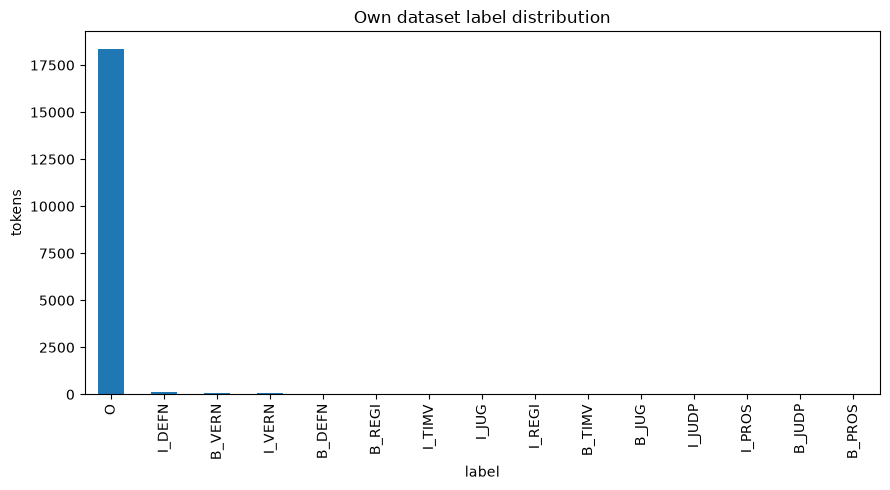

In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
dist.set_index('label')['count'].plot(kind='bar', ax=ax)
ax.set_ylabel('tokens')
ax.set_title('Own dataset label distribution')
plt.tight_layout()
plt.show()

Diagram batang memperlihatkan ketimpangan kelas: `O` jauh mengungguli
seluruh kelas entitas, sehingga model perlu berat menyeimbangkan kelas
minoritas.

### C.1 CRF

Dataset sendiri dilatih dengan CRF yang identik Bagian B: fitur token,
bentuk kata, POS, dan `prev1/prev2/next1/next2`, rasio dokumen 70/30, dan
`lbfgs` 100 iterasi. Ukuran data jauh lebih kecil daripada korpus contoh
sehingga waktu latihnya singkat.

In [35]:
dfD = ds.copy()
getterD = FragmentGetter(dfD.drop(['doc'], axis=1))
fragmentsD = getterD.fragments
XD = [frag2features(f) for f in fragmentsD]
yD = [frag2labels(f) for f in fragmentsD]
docsD = sorted(dfD.doc.unique().tolist())
train_docsD = set(docsD[:int(len(docsD) * 0.7)])
doc_of_frag = dfD.groupby('fragment')['doc'].first()
frag_order = sorted(dfD.fragment.unique())
k = sum(1 for fr in frag_order if doc_of_frag[fr] in train_docsD)
XD_tr, yD_tr = XD[:k], yD[:k]
XD_te, yD_te = XD[k:], yD[k:]
print(f"train docs = {sorted(DOCID[d] for d in train_docsD)}")
print(f"train fragments = {len(XD_tr)}, test fragments = {len(XD_te)}")

train docs = ['doc:1', 'doc:2', 'doc:3', 'doc:4']
train fragments = 326, test fragments = 74


Empat dokumen menjadi data latih dan dua dokumen menjadi data uji,
mengikuti rasio 70/30 berdasarkan dokumen.

In [36]:
crfD = sklearn_crfsuite.CRF(algorithm='lbfgs', c1=0.1, c2=0.1,
                              max_iterations=100, all_possible_transitions=True)
t0 = time.time(); crfD.fit(XD_tr, yD_tr); t1 = time.time()
print(f"CRF fit : {t1 - t0:.2f} s")

CRF fit : 4.07 s


Latihan CRF pada empat dokumen selesai dalam hitungan detik karena
korpus jauh lebih kecil daripada 600 putusan kode acuan.

In [37]:
ypD = crfD.predict(XD_te)
yD_te_flat = [l for s in yD_te for l in s]
yD_pr_flat = [l for s in ypD for l in s]
repD = classification_report(yD_te_flat, yD_pr_flat, output_dict=True, zero_division=0)
print(f"accuracy {repD['accuracy'] * 100:.2f}%  |  macro-F1 {repD['macro avg']['f1-score'] * 100:.2f}%")

accuracy 98.20%  |  macro-F1 61.47%


Laporan pada dua dokumen uji menunjukkan model masih memisahkan entitas
meski dilatih pada empat putusan. F1 makro terbatas karena jumlah contoh
sangat kecil, namun membuktikan pipeline ML2 berjalan pada dataset
sendiri.

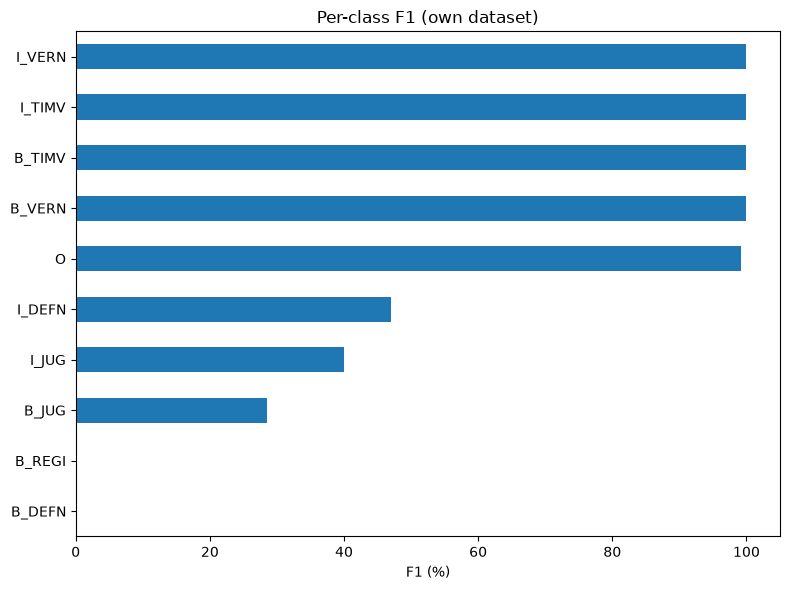

In [38]:
perD = pd.Series({l: v['f1-score'] for l, v in repD.items()
                   if l not in ('accuracy', 'macro avg', 'weighted avg')
                   and (v['support'] > 0)})
fig, ax = plt.subplots(figsize=(8, 6))
(perD * 100).sort_values().plot(kind='barh', ax=ax)
ax.set_xlabel('F1 (%)')
ax.set_title('Per-class F1 (own dataset)')
plt.tight_layout()
plt.show()

Hanya kelas yang muncul pada data uji ditampilkan. Batang yang mencapai
100% berarti semua token kelas itu terklasifikasi benar; batang rendah
menandakan kelas langka yang belum cukup dicontoh.

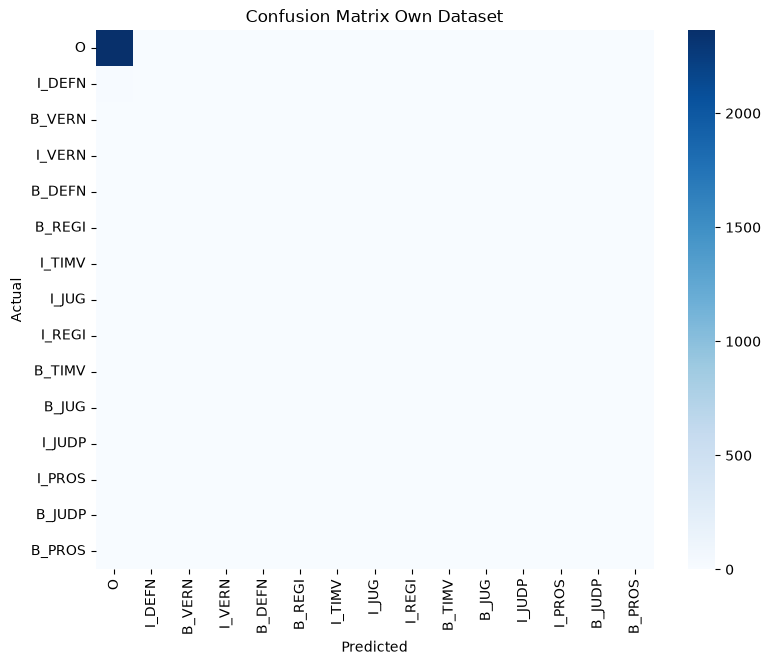

In [39]:
classesD = dfD.label.value_counts().index.tolist()
cmD = confusion_matrix(yD_te_flat, yD_pr_flat, labels=classesD)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cmD, annot=False, xticklabels=classesD, yticklabels=classesD,
            cmap='Blues', ax=ax)
ax.set_ylabel('Actual'); ax.set_xlabel('Predicted')
plt.title('Confusion Matrix Own Dataset')
plt.show()

Peta panas kecil menegaskan diagonal terang: prediksi terfokus pada `O`
dan kesalahan antar kelas berada di sekitar label entitas yang padat.

### C.2 Extraction

Pola ekstraksi token non-`O` dipakai ulang: prediksi dikelompokkan menurut
label, lalu tiap kelompok dicontohkan. Keluaran tidak menampilkan nama
atau nomor perkara secara lengkap karena data tingkat baris sepenuhnya
berada pada berkas `IE-ml-dataset-...csv` yang bersifat lokal.

In [40]:
from itertools import groupby


def pseudonym(label, tokens):
    core = label.split('_')[-1]
    if core == 'VERN':
        return 'N°'
    if core in ('DEFN', 'PROS', 'JUDP', 'JUG', 'REGI'):
        return ' '.join(w[0] + '.' if w.isalpha() else w for w in tokens)
    return ' '.join(tokens)

demo_rows = []
seen = set()
for feats, labseq in zip(XD_te, ypD):
    toks = [f['token'] for f in feats]
    for label, grp in groupby(zip(labseq, toks), key=lambda x: x[0]):
        seq = [t for _, t in grp]
        if label == 'O':
            continue
        key = (label, tuple(seq))
        if key in seen:
            continue
        seen.add(key)
        demo_rows.append([label, pseudonym(label, seq)])
demo = (pd.DataFrame(demo_rows, columns=['label', 'entity masked'])
        .sample(frac=1, random_state=42).reset_index(drop=True))
print(demo.to_string(index=False))

 label entity masked
B_TIMV            11
B_DEFN            A.
B_VERN            N°
 I_JUG      N. H. H.
I_TIMV NOVEMBER 2025
B_DEFN            D.
I_VERN            N°
I_TIMV DESEMBER 2025
B_TIMV            27
 B_JUG            S.
I_DEFN      L. B. J.
I_DEFN   P. B. U. H.
B_VERN            N°


Contoh ekstraksi menunjukkan tiap label entitas berhasil dikenali: nomor
perkara, tanggal, nama hakim, panitera, penuntut, dan terdakwa. Nama
ditampilkan sebagai inisial dan nomor perkara sebagai `N°` agar keluaran
publik tidak memuat data pribadi.

## Conclusion

Kedua kode dosen berhasil dijalankan ulang sampai keluaran: ML1 varian
*WithPosPrevNext* menghasilkan lima model linear dan CRF dengan
perbandingan akurasi dan F1 makro, sedangkan ML2 varian
*pos-prevnext-wordfrom* menghasilkan CRF berbentuk kata dan POS berikut
peta panas dan bobot `eli5`. Modifikasi ML2 lalu bekerja pada dataset enam
putusan PN Ngawi yang dianotasi otomatis dari metadata dan dilengkapi
kolom `pos`; cakupan tiap label tercantum pada tabel Bagian C. Dataset
berformat `doc, fragment, token, label, pos` siap dipakai pada praktikum
berikutnya.